# Resource allocation

We plan where roving medical teams start and how masks and nebulizer kits are split across barangays on one date,
and compare the plan with a distance-only plan on the 2026 report days. Outputs:

1. `data/processed/health_facility_bases.csv`: candidate team bases, health facilities within 5 km of the study area
2. `results/tables/allocation_comparison.csv`: vulnerable residents of reported barangays inside each plan's coverage, per 2026 report day
3. `results/tables/allocation_grid.csv`: the same comparison for 3, 5 and 8 teams and a reach of 5, 10 and 15 km
4. `results/tables/example_plan.csv`, `results/tables/example_plan_bases.csv` and `results/figures/example_plan_map.png`: both plans on the 2026 report day with the most reported barangays

Each plan uses only the health impact rows of its own date, and nothing is fit in this notebook.

## Setup

In [1]:
import json
import sys
from pathlib import Path

import geopandas as gpd
import matplotlib.pyplot as plt
import pandas as pd
from matplotlib.lines import Line2D
from matplotlib.patches import Patch

ROOT = Path.cwd() if (Path.cwd() / "requirements.txt").exists() else Path.cwd().parent
sys.path.insert(0, str(ROOT))
from src import allocation, geo

RAW = ROOT / "data" / "raw"
PROCESSED = ROOT / "data" / "processed"
REPORT_LOG = ROOT / "data" / "report_log" / "report_log.csv"
RESULTS = ROOT / "results"
FIGURES = RESULTS / "figures"
TABLES = RESULTS / "tables"
for folder in (FIGURES, TABLES):
    folder.mkdir(parents=True, exist_ok=True)

TRAIN_END = pd.Timestamp("2025-12-31")
BASE_BUFFER_KM = 5
K_TEAMS = 5
MAX_KM = 10
GRID_K_TEAMS = [3, 5, 8]
GRID_MAX_KM = [5, 10, 15]
# facility types kept in notebook 01
HF_AMENITY = {"hospital", "clinic", "doctors", "health_post"}
HF_HEALTHCARE = {"hospital", "clinic", "doctor"}

pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 40)


def show(df, name):
    """Print row count and missing values per column."""
    print(f"{name}: {len(df):,} rows x {df.shape[1]} columns")
    na = df.isna().sum()
    na = na[na > 0]
    print("  missing:", "none" if na.empty else na.to_dict())


metrics = {}

## Load data

In [2]:
barangays = (pd.read_csv(PROCESSED / "barangays_study_area.csv")
             .rename(columns={"adm4_psgc": "psgc_code", "adm4_en": "barangay"}))
show(barangays, "barangays_study_area")
assert len(barangays) == 216 and barangays["psgc_code"].is_unique

polygons = gpd.read_file(RAW / "barangays_negros.geojson")
show(polygons.drop(columns="geometry"), "barangays_negros")
polygons = (polygons[polygons["adm4_psgc"].isin(barangays["psgc_code"])]
            .rename(columns={"adm4_psgc": "psgc_code"})[["psgc_code", "geometry"]]
            .to_crs(32651))
show(polygons.drop(columns="geometry"), "study barangay polygons")
assert len(polygons) == 216

barangays_study_area: 216 rows x 19 columns
  missing: none
barangays_negros: 1,219 rows x 11 columns
  missing: none
study barangay polygons: 216 rows x 1 columns
  missing: none


Reported exposures come from the report log, joined by PSGC code. We keep 2026 event dates and barangays in the
study area; rows without a PSGC code cannot be joined and are dropped.

In [3]:
report_log = pd.read_csv(REPORT_LOG, usecols=["event_date", "psgc_code"], parse_dates=["event_date"])
report_log["psgc_code"] = report_log["psgc_code"].astype("Int64")
show(report_log, "report_log")

reported = (report_log.dropna(subset=["psgc_code"])
            .astype({"psgc_code": "int64"})
            .rename(columns={"event_date": "date"}))
show(reported, "report_log with a PSGC code")
reported = (reported[(reported["date"] > TRAIN_END) & reported["psgc_code"].isin(barangays["psgc_code"])]
            .drop_duplicates(["date", "psgc_code"])
            .reset_index(drop=True))
show(reported, "2026 reported barangay-days in the study area")
print(reported.groupby(reported["date"].dt.date).size().rename("reported barangays").to_string())

report_log: 243 rows x 2 columns
  missing: {'psgc_code': 1}
report_log with a PSGC code: 242 rows x 2 columns
  missing: none
2026 reported barangay-days in the study area: 92 rows x 2 columns
  missing: none
date
2026-02-19    27
2026-02-26    22
2026-03-15    16
2026-07-09    16
2026-10-10    11


The study-area table has no municipality name, so names come from the `Mun` column of the 2020 census, joined by
PSGC code.

In [4]:
census = pd.read_excel(RAW / "2020-census-total-popn_single-age_malefemale_admin4.xlsx", sheet_name="Brgy_adm4",
                       usecols=["BgyCode_new", "Mun"])
show(census, "census")
census["psgc_code"] = pd.to_numeric(census["BgyCode_new"].str.replace("PH", "", regex=False), errors="coerce")
municipalities = (census[census["psgc_code"].isin(barangays["psgc_code"])]
                  .astype({"psgc_code": "int64"})
                  .rename(columns={"Mun": "municipality"})[["psgc_code", "municipality"]])
show(municipalities, "census rows for study barangays")
assert len(municipalities) == 216 and municipalities["psgc_code"].is_unique

census: 42,041 rows x 2 columns
  missing: none
census rows for study barangays: 216 rows x 2 columns
  missing: none


## Candidate bases

Roving teams start from a health facility in the Humanitarian OpenStreetMap Team (2026) export. We keep the facility
types of notebook 01 (hospital, clinic, doctors, health post) within 5 km of the study area, the union of the 216
barangay polygons, so a team can also start just outside it, and keep one row per OSM id.

In [5]:
hf = gpd.read_file(f"zip://{(RAW / 'hotosm_phl_health_facilities_osm_geojson.zip').as_posix()}!health_facilities.geojson")
show(hf.drop(columns="geometry"), "health_facilities")
hf = hf[hf["amenity"].isin(HF_AMENITY) | hf["healthcare"].isin(HF_HEALTHCARE)].to_crs(32651)
hf["geometry"] = hf.geometry.centroid
show(hf[["id", "amenity", "healthcare"]], "health_facilities (kept types)")

study_area = polygons.union_all().buffer(BASE_BUFFER_KM * 1000)
hf = hf[hf.within(study_area)]
show(hf[["id", "name", "amenity"]], f"facilities within {BASE_BUFFER_KM} km of the study area")
print("rows sharing an OSM id with another row:", hf["id"].duplicated(keep=False).sum())
hf = hf.drop_duplicates("id")
show(hf[["id", "name", "amenity"]], "facilities (one row per OSM id)")

health_facilities: 19,129 rows x 24 columns
  missing: {'name': 1132, 'name_en': 18553, 'name_fil': 19126, 'amenity': 1959, 'building': 15190, 'healthcare': 5763, 'healthcare_speciality': 16809, 'operator_type': 15708, 'capacity_persons': 18233, 'addr_full': 18993, 'addr_city': 14332, 'source': 19129, 'adm1_pcode': 11, 'adm1_name': 11, 'adm2_pcode': 11, 'adm2_name': 11, 'adm3_pcode': 11, 'adm3_name': 11, 'adm4_pcode': 11, 'adm4_name': 11, 'name_latin': 1121}
health_facilities (kept types): 8,203 rows x 3 columns
  missing: {'amenity': 122, 'healthcare': 2794}
facilities within 5 km of the study area: 50 rows x 3 columns
  missing: {'name': 3}
rows sharing an OSM id with another row: 6
facilities (one row per OSM id): 47 rows x 3 columns
  missing: {'name': 3}


In [6]:
lonlat = hf.geometry.to_crs(4326)
bases = pd.DataFrame({"base_id": hf["id"].to_numpy(), "name": hf["name"].to_numpy(),
                      "amenity": hf["amenity"].to_numpy(), "lat": lonlat.y.to_numpy(), "lon": lonlat.x.to_numpy()})
bases["dist_crater_km"] = geo.haversine_km(geo.CRATER_LAT, geo.CRATER_LON, bases["lat"], bases["lon"])
bases = bases.sort_values(["dist_crater_km", "base_id"], ignore_index=True)
show(bases, "health_facility_bases")
bases.to_csv(PROCESSED / "health_facility_bases.csv", index=False)
print(bases["amenity"].value_counts().to_string())
print(f"distance to the crater: {bases['dist_crater_km'].min():.1f} to {bases['dist_crater_km'].max():.1f} km")

health_facility_bases: 47 rows x 6 columns
  missing: {'name': 3}
amenity
health_post    25
clinic          9
hospital        8
doctors         5
distance to the crater: 7.2 to 36.6 km


47 candidate bases remain: 25 health posts, 9 clinics, 8 hospitals and 5 doctors' offices. The closest is
7.2 km from the crater and the farthest 36.6 km; three have no name in OpenStreetMap.

## Coverage rule

A base covers a barangay if 1.4 x the great-circle distance from the base to the barangay centroid is at most
max_km. The factor 1.4 is our rough allowance for winding mountain roads, an assumption, not a measured road
distance.

In [7]:
allocation.load_plan_inputs.cache_clear()  # re-read the bases saved above if this cell runs again
inputs = allocation.load_plan_inputs()
show(inputs["barangays"], "plan barangays")
show(inputs["bases"], "plan bases")
show(inputs["daily"], "plan barangay-days")
print(f"road distance matrix: {inputs['road_km'].shape[0]} barangays x {inputs['road_km'].shape[1]} bases")

in_reach_rows = []
for max_km in GRID_MAX_KM:
    reachable = (inputs["road_km"] <= max_km).any(axis=1)
    reach_brgy = barangays.set_index("psgc_code").loc[reachable.index[reachable]]
    in_reach_rows.append({"max_km": max_km, "barangays_in_reach": int(reachable.sum()),
                          "barangays_out_of_reach": int((~reachable).sum()),
                          "vulnerable_in_reach_share": (reach_brgy[["pop_under5", "pop_60plus"]].sum().sum()
                                                        / barangays[["pop_under5", "pop_60plus"]].sum().sum())})
in_reach = pd.DataFrame(in_reach_rows)
print("Barangays within reach of at least one candidate base")
in_reach.round(3)

plan barangays: 216 rows x 7 columns
  missing: none
plan bases: 47 rows x 6 columns
  missing: {'name': 3}
plan barangay-days: 221,184 rows x 4 columns
  missing: none
road distance matrix: 216 barangays x 47 bases
Barangays within reach of at least one candidate base


,max_km,barangays_in_reach,barangays_out_of_reach,vulnerable_in_reach_share
0,5,71,145,0.428
1,10,134,82,0.739
2,15,170,46,0.887


With a 10 km road reach, 82 of the 216 barangays are out of reach of every candidate base, so no plan can cover
them. The 134 barangays within reach hold 73.9% of the study area's under-5 and 60+ residents.

## Supply scenario

Masks go to barangays in whole units, up to each barangay's need, including barangays outside team coverage, since
masks can also travel through municipal health offices. Nebulizer kits are used by health workers, so they go to the
team bases: each covered barangay is assigned to its nearest open base, and kits are split across bases with
largest-remainder rounding.

- Model plan: mask need = pop_total x p_exposed, served highest weight per resident first, where weight =
  extra_under5 + extra_60plus under the main scenario (40 ug/m3). Kits follow the weight assigned to each base.
- Distance-only plan, with no model output: mask need = pop_total, served closest barangays first. Kits follow the
  under-5 and 60+ residents assigned to each base.

The default 135,000 masks and 349 kits equal what DOH distributed after the December 2024 eruption (Bayoran, 2025);
they are a scenario, not a count of current stock.

In [8]:
report_dates = sorted(reported["date"].unique())
supply_need = pd.DataFrame([{"date": date.date(),
                             "model_mask_need": int(allocation.day_table(date, inputs)["mask_need"].astype(int).sum())}
                            for date in report_dates])
supply_need["model_masks_share_of_need"] = (allocation.SCENARIO_MASKS / supply_need["model_mask_need"]).clip(upper=1)
distance_mask_need = int(barangays["pop_total"].sum())
print(f"scenario: {allocation.SCENARIO_MASKS:,} masks")
print(f"distance-only mask need (pop_total) on every day: {distance_mask_need:,}, "
      f"so the scenario meets {allocation.SCENARIO_MASKS / distance_mask_need:.1%} of it")
print("model-plan mask need in whole units on each 2026 report day")
supply_need.round(3)

scenario: 135,000 masks
distance-only mask need (pop_total) on every day: 996,899, so the scenario meets 13.5% of it
model-plan mask need in whole units on each 2026 report day


,date,model_mask_need,model_masks_share_of_need
0,2026-02-19,116848,1.000
1,2026-02-26,258326,0.523
2,2026-03-15,207838,0.650
3,2026-07-09,128475,1.000
4,2026-10-10,227075,0.595


Model-plan mask need on the 2026 report days is 116,848 to 258,326, so the scenario meets all of it on two days
and 52% to 65% on the other three. The distance-only mask need is the whole population, 996,899, so the scenario
meets 13.5% of it.

## Comparison with the distance-only plan

For each 2026 report day we build both plans from that day's health impact rows only, with 5 teams, a 10 km reach
and the scenario supplies. The model plan opens the 5 bases that cover the largest total weight (maximum coverage
integer program, CBC through PuLP), the distance-only plan the 5 bases closest to the crater, and we count the
under-5 and 60+ residents of the barangays reported exposed that day inside each plan's coverage.

In [9]:
comparison = allocation.compare_with_distance_plan(reported, K_TEAMS, MAX_KM, inputs=inputs)
show(comparison, "allocation_comparison")
comparison.to_csv(TABLES / "allocation_comparison.csv", index=False)

total_model, total_distance = comparison["model_plan"].sum(), comparison["distance_plan"].sum()
days_more = int((comparison["difference"] > 0).sum())
days_tied = int((comparison["difference"] == 0).sum())
days_fewer = int((comparison["difference"] < 0).sum())
print(f"under-5 and 60+ residents of reported barangays covered, {len(comparison)} days: "
      f"model plan {total_model:,}, distance-only plan {total_distance:,}, difference {total_model - total_distance:,}")
print(f"share of reported under-5 and 60+ residents covered: model plan "
      f"{total_model / comparison['reported_vulnerable'].sum():.1%}, "
      f"distance-only plan {total_distance / comparison['reported_vulnerable'].sum():.1%}")
print(f"model plan covers more on {days_more} of {len(comparison)} days ({days_more / len(comparison):.0%}), "
      f"the same on {days_tied}, fewer on {days_fewer}")
print("target, cover more than distance-only:", "met" if total_model > total_distance else "not met")
comparison

allocation_comparison: 5 rows x 6 columns
  missing: none
under-5 and 60+ residents of reported barangays covered, 5 days: model plan 51,630, distance-only plan 20,158, difference 31,472
share of reported under-5 and 60+ residents covered: model plan 51.7%, distance-only plan 20.2%
model plan covers more on 4 of 5 days (80%), the same on 1, fewer on 0
target, cover more than distance-only: met


,date,reported_barangays,reported_vulnerable,model_plan,distance_plan,difference
0,2026-02-19,27,24426,13979,892,13087
1,2026-02-26,22,23430,14565,892,13673
2,2026-03-15,16,16145,7600,5348,2252
3,2026-07-09,16,22360,13026,13026,0
4,2026-10-10,11,13467,2460,0,2460


Over the five days the model plan covers 51,630 under-5 and 60+ residents of reported barangays and the
distance-only plan 20,158 (51.7% and 20.2% of the 99,828 reported), so the target is met. The model plan covers
more on 4 of the 5 days (80%, a rough figure from five days) and the same on 2026-07-09, when 12 of the 16 reported
barangays lay east or south-east of the crater, on the same side as the five facilities closest to it, and both
plans cover the same 12.

## Supplies reaching reported barangays

The target is about team coverage, but we also count the masks each plan sends to the barangays reported exposed
and the kits held at bases that serve at least one reported barangay (one among those assigned to the base), with
the same plans as above.

In [10]:
supply_rows = []
for date in report_dates:
    codes = set(reported.loc[reported["date"] == date, "psgc_code"])
    row = {"date": date.date()}
    for prefix, make in [("model", allocation.make_plan), ("distance", allocation.make_distance_plan)]:
        plan = make(date, K_TEAMS, MAX_KM, inputs=inputs)
        plan_rows = plan["barangays"]
        serving = plan_rows.loc[plan_rows["covered"] & plan_rows["psgc_code"].isin(codes), "nearest_base_id"]
        row |= {f"{prefix}_masks_to_reported": int(plan_rows.loc[plan_rows["psgc_code"].isin(codes), "masks"].sum()),
                f"{prefix}_kits_serving_reported": int(plan["bases"].loc[plan["bases"]["base_id"].isin(serving),
                                                                          "kits"].sum()),
                f"{prefix}_bases_with_kits": int((plan["bases"]["kits"] > 0).sum())}
    supply_rows.append(row)
supply_check = pd.DataFrame(supply_rows)
show(supply_check, "supplies to reported barangays")
supply_totals = supply_check.drop(columns="date").sum()
print(f"masks to reported barangays: model plan {supply_totals['model_masks_to_reported']:,}, "
      f"distance-only plan {supply_totals['distance_masks_to_reported']:,}")
print(f"kits at bases serving a reported barangay: model plan {supply_totals['model_kits_serving_reported']:,}, "
      f"distance-only plan {supply_totals['distance_kits_serving_reported']:,}, "
      f"of {len(report_dates) * allocation.SCENARIO_KITS:,} handed out")
supply_check

supplies to reported barangays: 5 rows x 7 columns
  missing: none
masks to reported barangays: model plan 249,103, distance-only plan 229,714
kits at bases serving a reported barangay: model plan 1,039, distance-only plan 727, of 1,745 handed out


,date,model_masks_to_reported,model_kits_serving_reported,model_bases_with_kits,distance_masks_to_reported,distance_kits_serving_reported,distance_bases_with_kits
0,2026-02-19,53266,330,5,34020,112,5
1,2026-02-26,59138,238,5,43022,112,5
2,2026-03-15,46097,149,5,65073,154,5
3,2026-07-09,61290,245,5,57176,349,5
4,2026-10-10,29312,77,5,30423,0,5


Over the five days:

- Masks to reported barangays: 249,103 in the model plan and 229,714 in the distance-only plan, which sends more on
  2026-03-15 (65,073 against 46,097) and 2026-10-10 (30,423 against 29,312). The distance-only plan uses no daily
  input, so it gives all 135,000 masks to the 23 barangays closest to the crater every day.
- Kits at bases serving a reported barangay: 1,039 of the 1,745 handed out in the model plan and 727 in the
  distance-only plan, which has more on 2026-03-15 (154 against 149) and 2026-07-09 (349 against 245).

## Sensitivity grid

The same comparison for 3, 5 and 8 teams and a reach of 5, 10 and 15 km shows how much the result depends on these
settings. We do not use it to choose settings; the plan stays at 5 teams and 10 km.

In [11]:
grid_rows = []
for k_teams in GRID_K_TEAMS:
    for max_km in GRID_MAX_KM:
        result = allocation.compare_with_distance_plan(reported, k_teams, max_km, inputs=inputs)
        grid_rows.append({"k_teams": k_teams, "max_km": max_km, "report_days": len(result),
                          "model_plan": result["model_plan"].sum(), "distance_plan": result["distance_plan"].sum(),
                          "difference": result["difference"].sum(),
                          "days_model_more": int((result["difference"] > 0).sum()),
                          "days_tied": int((result["difference"] == 0).sum()),
                          "days_distance_more": int((result["difference"] < 0).sum())})
grid = pd.DataFrame(grid_rows)
show(grid, "allocation_grid")
grid.to_csv(TABLES / "allocation_grid.csv", index=False)
grid

allocation_grid: 9 rows x 9 columns
  missing: none


,k_teams,max_km,report_days,model_plan,distance_plan,difference,days_model_more,days_tied,days_distance_more
0,3,5,5,21094,9347,11747,3,2,0
1,3,10,5,42215,17994,24221,4,1,0
2,3,15,5,72751,34358,38393,5,0,0
3,5,5,5,21094,10331,10763,3,2,0
4,5,10,5,51630,20158,31472,4,1,0
5,5,15,5,90863,36748,54115,5,0,0
6,8,5,5,22214,15177,7037,2,3,0
7,8,10,5,58592,39996,18596,4,0,1
8,8,15,5,93855,80514,13341,5,0,0


The model plan covers more in total in all nine settings. Per day it covers fewer only once, with 8 teams and a
10 km reach on 2026-07-09 (2,390 fewer), the day most reports came from the east side; with a 5 km reach the plans
tie on 2 or 3 of the 5 days.

## Example plan

Both plans on the 2026 report day with the most reported barangays in the study area, with the default settings.

In [12]:
example_date = pd.Timestamp(comparison.loc[comparison["reported_barangays"].idxmax(), "date"])
model_plan = allocation.make_plan(example_date, K_TEAMS, MAX_KM, inputs=inputs)
distance_plan = allocation.make_distance_plan(example_date, K_TEAMS, MAX_KM, inputs=inputs)
print(f"example date: {example_date.date()}, "
      f"{comparison.loc[comparison['date'] == example_date.date(), 'reported_barangays'].item()} reported barangays")

base_label = bases.set_index("base_id")["name"].fillna("unnamed " + bases.set_index("base_id")["amenity"])
example_bases = pd.concat([plan["bases"].assign(plan=prefix) for prefix, plan in
                           [("model", model_plan), ("distance", distance_plan)]], ignore_index=True)
example_bases["name"] = example_bases["base_id"].map(base_label)
example_bases = example_bases[["plan", "base_id", "name", "amenity", "lat", "lon", "dist_crater_km",
                               "barangays_in_reach", "barangays_assigned", "weight_assigned", "vulnerable_assigned",
                               "kits"]]
show(example_bases, "example_plan_bases")
example_bases.to_csv(TABLES / "example_plan_bases.csv", index=False, float_format="%.6g")
example_bases.drop(columns=["lat", "lon"]).round({"dist_crater_km": 1, "weight_assigned": 5})

example date: 2026-02-19, 27 reported barangays
example_plan_bases: 10 rows x 12 columns
  missing: none


,plan,base_id,name,amenity,dist_crater_km,barangays_in_reach,barangays_assigned,weight_assigned,vulnerable_assigned,kits
0,model,way/388895933,Masulog Barangay Health Center,health_post,7.2,11,11,0.00086,11679,39
1,model,way/1350325670,San Miguel Barangay Health Station,health_post,12.1,13,12,0.00402,9959,181
2,model,way/685791670,La Castellana Rural Health Unit,doctors,15.9,13,11,0.00059,10792,26
3,model,way/1308275136,Cansilayan Barangay Health Station,health_post,20.6,16,16,0.00043,14183,19
4,model,node/12819059659,Barangay Ⅱ Health Station,health_post,23.6,27,26,0.00188,19161,84
5,distance,way/388895933,Masulog Barangay Health Center,health_post,7.2,11,7,0.00056,6649,112
6,distance,way/310683911,Canlaon District Hospital,hospital,9.0,13,3,0.00015,2520,42
7,distance,node/11743401369,unnamed doctors,doctors,10.0,14,2,0.00020,3179,53
8,distance,way/1290960916,Bayog Barangay Health Station,health_post,10.3,13,3,0.00003,3245,54
9,distance,way/1353323366,Canlaon City Rural Health Unit,doctors,11.4,16,7,0.00011,5247,88


In [13]:
PLAN_COLUMNS = {"covered": "covered", "nearest_base_id": "base", "masks": "masks"}
example_reported = set(reported.loc[reported["date"] == example_date, "psgc_code"])
example_plan = (model_plan["barangays"]
                [["psgc_code", "dist_km", "pop_total", "pop_under5", "pop_60plus", "p_exposed", "weight"]]
                .rename(columns={"weight": "extra_under5_60plus"})
                .merge(barangays[["psgc_code", "barangay", "province"]], on="psgc_code", how="left", validate="1:1")
                .merge(municipalities, on="psgc_code", how="left", validate="1:1"))
example_plan["reported"] = example_plan["psgc_code"].isin(example_reported)
for prefix, plan in [("model", model_plan), ("distance", distance_plan)]:
    plan_rows = plan["barangays"].set_index("psgc_code")
    for col, label in PLAN_COLUMNS.items():
        example_plan[f"{prefix}_{label}"] = example_plan["psgc_code"].map(plan_rows[col])
    # a base is listed only for covered barangays
    example_plan[f"{prefix}_base"] = (example_plan[f"{prefix}_base"].map(base_label)
                                      .where(example_plan[f"{prefix}_covered"]))
example_plan = (example_plan[["psgc_code", "barangay", "municipality", "province", "dist_km", "pop_total",
                              "pop_under5", "pop_60plus", "p_exposed", "extra_under5_60plus", "reported",
                              *[f"{p}_{label}" for p in ["model", "distance"] for label in PLAN_COLUMNS.values()]]]
                .sort_values("extra_under5_60plus", ascending=False, ignore_index=True))
show(example_plan, "example_plan")
example_plan.to_csv(TABLES / "example_plan.csv", index=False, float_format="%.6g")

example_summary = pd.DataFrame({
    prefix: {"barangays_covered": int(example_plan[f"{prefix}_covered"].sum()),
             "weight_covered_share": example_plan.loc[example_plan[f"{prefix}_covered"], "extra_under5_60plus"].sum()
                                     / example_plan["extra_under5_60plus"].sum(),
             "reported_barangays_covered": int((example_plan[f"{prefix}_covered"] & example_plan["reported"]).sum()),
             "masks": int(example_plan[f"{prefix}_masks"].sum()),
             "barangays_with_masks": int((example_plan[f"{prefix}_masks"] > 0).sum()),
             "bases_with_kits": int((example_bases.loc[example_bases["plan"] == prefix, "kits"] > 0).sum())}
    for prefix in ["model", "distance"]})
print(f"{len(example_reported)} reported barangays on {example_date.date()}")
example_summary.round(3)

example_plan: 216 rows x 17 columns
  missing: {'model_base': 140, 'distance_base': 194}
27 reported barangays on 2026-02-19


,model,distance
barangays_covered,76.000,22.000
weight_covered_share,0.769,0.103
reported_barangays_covered,18.000,1.000
masks,116848.000,135000.000
barangays_with_masks,201.000,23.000
bases_with_kits,5.000,5.000


On 2026-02-19, 23 of the 27 reported barangays lay west or south-west of the crater.

- Coverage: the model plan puts four of its five bases west of the crater and covers 18 of the 27 reported
  barangays (76.9% of the day's weight); the distance-only plan's bases are all east or south-east of the crater
  and cover 1 (10.3%).
- Masks: the model plan gives 116,848 masks to 201 barangays, which meets every barangay's need that day; the
  distance-only plan gives all 135,000 to the 23 barangays closest to the crater.
- Kits: San Miguel Barangay Health Station gets 181 of the model plan's 349 kits, because the barangays assigned to
  it carry the most weight; in the distance-only plan, Masulog Barangay Health Center gets the most, 112, because
  it serves the most under-5 and 60+ residents.

The map shows each plan's bases, the barangays inside their 10 km road reach, and the barangays reported exposed
on the example day.

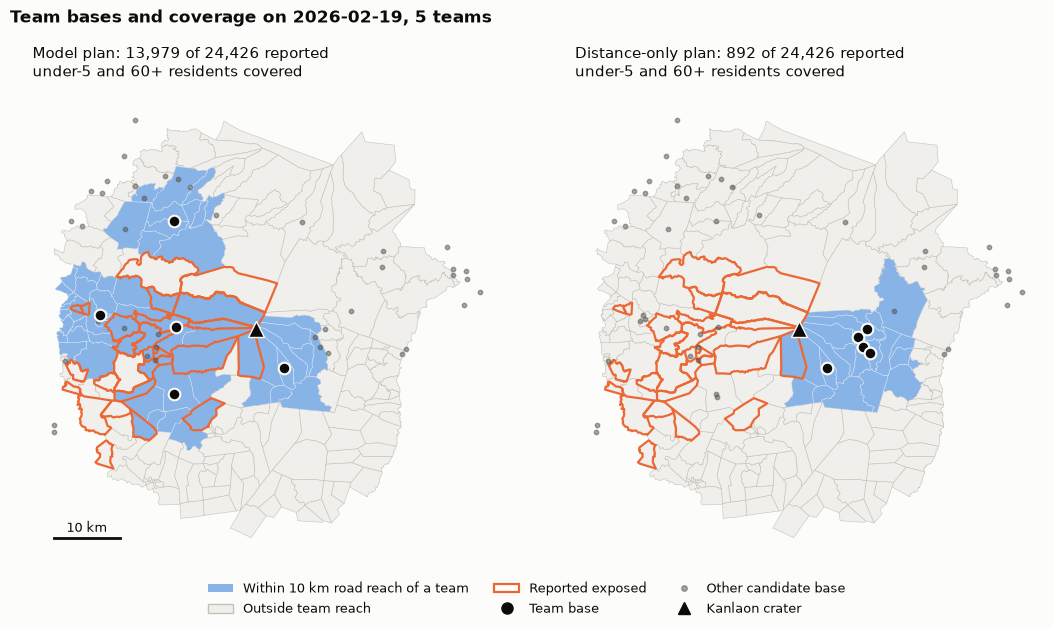

In [14]:
COVERED_COLOR, REPORTED_COLOR = "#2a78d6", "#eb6834"
SURFACE, NOT_COVERED_COLOR, EDGE_COLOR, INK, MUTED_INK = "#fcfcfb", "#f0efec", "#c3c2b7", "#0b0b0b", "#52514e"
crater_xy = gpd.GeoSeries(gpd.points_from_xy([geo.CRATER_LON], [geo.CRATER_LAT]), crs=4326).to_crs(32651).iloc[0]
base_points = gpd.GeoDataFrame(bases, geometry=gpd.points_from_xy(bases["lon"], bases["lat"]), crs=4326).to_crs(32651)
example_map = polygons.merge(example_plan[["psgc_code", "reported", "model_covered", "distance_covered"]],
                             on="psgc_code", how="left", validate="1:1")

fig, axes = plt.subplots(1, 2, figsize=(11, 6.2), facecolor=SURFACE)
for ax, prefix, plan, title in [(axes[0], "model", model_plan, "Model plan"),
                                (axes[1], "distance", distance_plan, "Distance-only plan")]:
    ax.set_facecolor(SURFACE)
    covered = example_map[f"{prefix}_covered"]
    example_map[~covered].plot(ax=ax, color=NOT_COVERED_COLOR, edgecolor=EDGE_COLOR, linewidth=0.4)
    example_map[covered].plot(ax=ax, color=COVERED_COLOR, alpha=0.55, edgecolor=SURFACE, linewidth=0.4)
    example_map[example_map["reported"]].plot(ax=ax, facecolor="none", edgecolor=REPORTED_COLOR, linewidth=1.6)
    base_points[~base_points["base_id"].isin(plan["bases"]["base_id"])].plot(
        ax=ax, marker="o", markersize=10, color=MUTED_INK, alpha=0.5)
    base_points[base_points["base_id"].isin(plan["bases"]["base_id"])].plot(
        ax=ax, marker="o", markersize=70, color=INK, edgecolor=SURFACE, linewidth=1.5, zorder=4)
    ax.plot(crater_xy.x, crater_xy.y, marker="^", markersize=11, color=INK, markeredgecolor=SURFACE, zorder=5)
    covered_people = comparison.loc[comparison["date"] == example_date.date(), f"{prefix}_plan"].item()
    reported_people = comparison.loc[comparison["date"] == example_date.date(), "reported_vulnerable"].item()
    ax.set_title(f"{title}: {covered_people:,} of {reported_people:,} reported\nunder-5 and 60+ residents covered",
                 fontsize=11, color=INK, loc="left")
    ax.set_axis_off()

x0, y0 = example_map.total_bounds[[0, 1]]
axes[0].plot([x0, x0 + 10_000], [y0, y0], color=INK, linewidth=2)
axes[0].text(x0 + 5_000, y0 + 900, "10 km", ha="center", fontsize=9, color=INK)
legend_items = [Patch(facecolor=COVERED_COLOR, alpha=0.55, label="Within 10 km road reach of a team"),
                Patch(facecolor=NOT_COVERED_COLOR, edgecolor=EDGE_COLOR, label="Outside team reach"),
                Patch(facecolor="none", edgecolor=REPORTED_COLOR, linewidth=1.6, label="Reported exposed"),
                Line2D([], [], marker="o", linestyle="none", markersize=8, color=INK, label="Team base"),
                Line2D([], [], marker="o", linestyle="none", markersize=4, color=MUTED_INK, alpha=0.5,
                       label="Other candidate base"),
                Line2D([], [], marker="^", linestyle="none", markersize=9, color=INK, label="Kanlaon crater")]
fig.legend(handles=legend_items, loc="lower center", ncol=3, frameon=False, fontsize=9, labelcolor=INK)
fig.suptitle(f"Team bases and coverage on {example_date.date()}, {K_TEAMS} teams", fontsize=12, color=INK,
             x=0.02, y=0.99, ha="left", fontweight="bold")
fig.tight_layout(rect=(0, 0.08, 1, 0.93))
fig.savefig(FIGURES / "example_plan_map.png", dpi=150, facecolor=SURFACE)
plt.show()

## Save metrics

In [15]:
metrics["allocation"] = {
    "k_teams": K_TEAMS,
    "max_km": MAX_KM,
    "road_factor": allocation.ROAD_FACTOR,
    "scenario_masks": allocation.SCENARIO_MASKS,
    "scenario_kits": allocation.SCENARIO_KITS,
    "n_candidate_bases": len(bases),
    "barangays_out_of_reach": in_reach.set_index("max_km")["barangays_out_of_reach"].to_dict(),
    "report_days": len(comparison),
    "vulnerable_covered_model": int(total_model),
    "vulnerable_covered_distance": int(total_distance),
    "reported_vulnerable": int(comparison["reported_vulnerable"].sum()),
    "days_model_more": days_more,
    "days_tied": days_tied,
    "days_distance_more": days_fewer,
    "target_met": bool(total_model > total_distance),
    "masks_to_reported_model": int(supply_totals["model_masks_to_reported"]),
    "masks_to_reported_distance": int(supply_totals["distance_masks_to_reported"]),
    "kits_serving_reported_model": int(supply_totals["model_kits_serving_reported"]),
    "kits_serving_reported_distance": int(supply_totals["distance_kits_serving_reported"]),
    "example_date": str(example_date.date()),
}
metrics_path = RESULTS / "metrics.json"
all_metrics = json.loads(metrics_path.read_text()) if metrics_path.exists() else {}
all_metrics.update(metrics)
metrics_path.write_text(json.dumps(all_metrics, indent=2, default=float))
print("metrics keys:", list(all_metrics))

metrics keys: ['so2_next_day', 'drift_next_day', 'plume_index', 'exposure', 'health_impact', 'allocation']


## Limitations

- Coverage counts residents of reported barangays inside a team's reach, not people seen or treated, and teams
  have no capacity limit.
- Reach is 1.4 x the straight-line distance, not a road network or travel time.
- Candidate bases come from OpenStreetMap, which can miss facilities or list closed ones.
- The model plan follows the exposure model's p_exposed, so barangays that model misses are missed here too.
- Kits are split by the weight (model plan) or the under-5 and 60+ residents (distance-only plan) assigned to
  each base, not by the number of health workers there or how many nebulizers a base can use. A barangay
  in reach of several bases counts only toward the nearest.
- We first built the distance-only baseline with model-based needs and changed it to population-based needs so it
  uses no model output; with model-based needs, 988 of its kits sat at bases serving a reported barangay and it
  sent 254,237 masks to reported barangays.